### Part A: Conceptual Understanding

In [270]:
'''
1. What is Logistic Regression and why is it suitable for classification?
Logistic Regression is a supervised machine learning algorithm used for classification.
It predicts the probability of an outcome between 0 and 1 using the sigmoid function. 
It is suitable for binary classification problems like fraud detection and disease prediction.

2. Explain classification performance metrics and why accuracy alone is insufficient.
Classification metrics measure how well a model predicts different classes.
- Accuracy: Percentage of correct predictions.
- Precision: Correct positive predictions out of total predicted positives.
- Recall: Correctly identified positive cases out of actual positive cases.
- F1-Score: Harmonic mean of precision and recall.
- AUC-ROC: Measures the model's ability to distinguish between classes.
Accuracy alone is insufficient because it can be misleading when the dataset is imbalanced.

3. Define Type-I Error and Type-II Error in risk prediction.
- Type-I Error (False Positive): Predicting a negative case as positive. 
Example: Identifying a genuine transaction as fraud.
- Type-II Error (False Negative): Predicting a positive case as negative. 
Example: Identifying a fraudulent transaction as genuine.

4. Explain Precision, Recall, F1-Score, TPR, and FPR.
Precision: Measures how many predicted positive cases are actually positive.
Recall: Measures how many actual positive cases are correctly identified.
F1-Score: Harmonic mean of precision and recall.
TPR: Proportion of actual positive cases correctly identified.
FPR: Proportion of actual negative cases incorrectly predicted as positive.

5. What is AUC-ROC and how does it help in evaluating classifiers?
AUC-ROC is a performance measure used to evaluate classification models.
- ROC: Graph of True Positive Rate against False Positive Rate.
- AUC: Measures how well a model distinguishes between classes.
AUC = 1 indicates a perfect model, while AUC = 0.5 indicates random guessing.

6. Why does imbalanced data create problems in classification models?
Imbalanced data occurs when one class has significantly more observations than another.
Problems:
1. The model becomes biased towards the majority class.
2. It may fail to identify minority-class observations.
3. Accuracy can give misleading results.
Solutions: 
Oversampling, undersampling, SMOTE and class weighting.

'''

"\n1. What is Logistic Regression and why is it suitable for classification?\nLogistic Regression is a supervised machine learning algorithm used for classification.\nIt predicts the probability of an outcome between 0 and 1 using the sigmoid function. \nIt is suitable for binary classification problems like fraud detection and disease prediction.\n\n2. Explain classification performance metrics and why accuracy alone is insufficient.\nClassification metrics measure how well a model predicts different classes.\n- Accuracy: Percentage of correct predictions.\n- Precision: Correct positive predictions out of total predicted positives.\n- Recall: Correctly identified positive cases out of actual positive cases.\n- F1-Score: Harmonic mean of precision and recall.\n- AUC-ROC: Measures the model's ability to distinguish between classes.\nAccuracy alone is insufficient because it can be misleading when the dataset is imbalanced.\n\n3. Define Type-I Error and Type-II Error in risk prediction.\

In [271]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [272]:
df=pd.read_csv("D:\Risk_Alert_Classifier_Dataset_4600.csv.csv")
df.head()

<>:1: SyntaxWarning: invalid escape sequence '\R'
<>:1: SyntaxWarning: invalid escape sequence '\R'
C:\Users\Admin\AppData\Local\Temp\ipykernel_11780\2621768491.py:1: SyntaxWarning: invalid escape sequence '\R'
  df=pd.read_csv("D:\Risk_Alert_Classifier_Dataset_4600.csv.csv")


,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0


In [273]:
df.shape

(4600, 19)

In [274]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                4600 non-null   int64  
 1   age                        4460 non-null   float64
 2   gender                     4600 non-null   object 
 3   region                     4498 non-null   object 
 4   employment_type            4456 non-null   object 
 5   annual_income_inr          4434 non-null   float64
 6   credit_score               4384 non-null   float64
 7   credit_utilization_ratio   4453 non-null   float64
 8   missed_payments_12m        4600 non-null   int64  
 9   avg_late_payment_days      4600 non-null   float64
 10  monthly_transaction_count  4600 non-null   int64  
 11  monthly_spend_inr          4471 non-null   float64
 12  cash_advance_count_6m      4600 non-null   int64  
 13  complaints_last_6m         4600 non-null   int64

### Part B: Dataset Understanding and Preparation

In [275]:
#7. 
# Input Features
X=df.drop(['risk_status','customer_id','last_transaction_date'],axis=1)
# Target Variable
y=df['risk_status']

In [276]:
from sklearn.model_selection import train_test_split

In [277]:
#8.Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20,random_state=42,stratify=y)

In [278]:
from sklearn.impute import KNNImputer, SimpleImputer

In [279]:
#9.
# Identifying missing values 
print(df.isnull().sum())

customer_id                    0
age                          140
gender                         0
region                       102
employment_type              144
annual_income_inr            166
credit_score                 216
credit_utilization_ratio     147
missed_payments_12m            0
avg_late_payment_days          0
monthly_transaction_count      0
monthly_spend_inr            129
cash_advance_count_6m          0
complaints_last_6m             0
failed_login_attempts_3m       0
account_tenure_months          0
last_transaction_date          0
debt_balance_inr               0
risk_status                    0
dtype: int64


In [280]:
# Applying KNN imputer for numerical columns
num_cols = X_train.select_dtypes(include='number').columns
knn = KNNImputer(n_neighbors=5)
X_train[num_cols] = knn.fit_transform(X_train[num_cols])
X_test[num_cols] = knn.transform(X_test[num_cols])
print(X_train.isnull().sum())
print(X_test.isnull().sum())

#applying simple imputer for categorical columns
cat_cols = X_train.select_dtypes(include='object').columns
simple = SimpleImputer(strategy='most_frequent')
X_train[cat_cols] = simple.fit_transform(X_train[cat_cols])
X_test[cat_cols] = simple.transform(X_test[cat_cols])
print(X_train.isnull().sum())
print(X_test.isnull().sum())

age                            0
gender                         0
region                        78
employment_type              115
annual_income_inr              0
credit_score                   0
credit_utilization_ratio       0
missed_payments_12m            0
avg_late_payment_days          0
monthly_transaction_count      0
monthly_spend_inr              0
cash_advance_count_6m          0
complaints_last_6m             0
failed_login_attempts_3m       0
account_tenure_months          0
debt_balance_inr               0
dtype: int64
age                           0
gender                        0
region                       24
employment_type              29
annual_income_inr             0
credit_score                  0
credit_utilization_ratio      0
missed_payments_12m           0
avg_late_payment_days         0
monthly_transaction_count     0
monthly_spend_inr             0
cash_advance_count_6m         0
complaints_last_6m            0
failed_login_attempts_3m      0
account_ten

### Part C: Baseline Classification Model

In [281]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [282]:
# 10. Implementing Logistic Regression
# encoding categorical variables using one-hot encoding
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# scaling the features using StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# Creating model
lr = LogisticRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

In [283]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [284]:
# 11. Generate and Interpret
# Confusion Matrix
cm=confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Accuracy Score
print("\nAccuracy Score:")
print(accuracy_score(y_test, y_pred))

# Precision, Recall, F1-Score
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Confusion Matrix:
[[809   0]
 [  0 111]]

Accuracy Score:
1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       1.00      1.00      1.00       111

    accuracy                           1.00       920
   macro avg       1.00      1.00      1.00       920
weighted avg       1.00      1.00      1.00       920



In [285]:
# 12. Identify type-I and type-II errors from the confusion matrix
TN, FP, FN, TP = cm.ravel()
print("Type 1 Error:", FP)
print("Type 2 Error:", FN)

Type 1 Error: 0
Type 2 Error: 0


### Part D: Handling Imbalanced data

In [286]:
# 13.  demonstrate the impact of class imbalance on model performance
# model without handling class imbalance
lr = LogisticRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       1.00      1.00      1.00       111

    accuracy                           1.00       920
   macro avg       1.00      1.00      1.00       920
weighted avg       1.00      1.00      1.00       920



In [287]:
# model with class balancing
lr_bal = LogisticRegression(class_weight='balanced')
lr_bal.fit(X_train, y_train)
y_pred_bal = lr_bal.predict(X_test)
print(classification_report(y_test, y_pred_bal))


              precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       0.97      1.00      0.99       111

    accuracy                           1.00       920
   macro avg       0.99      1.00      0.99       920
weighted avg       1.00      1.00      1.00       920



In [288]:
from sklearn.metrics import recall_score, f1_score, roc_auc_score,precision_score

In [289]:
# comparing both models
print("Without Balancing:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nWith Balancing:")
print("Accuracy:", accuracy_score(y_test, y_pred_bal))
print("Recall:", recall_score(y_test, y_pred_bal))
print("F1 Score:", f1_score(y_test, y_pred_bal))

Without Balancing:
Accuracy: 1.0
Recall: 1.0
F1 Score: 1.0

With Balancing:
Accuracy: 0.9967391304347826
Recall: 1.0
F1 Score: 0.9866666666666667


In [290]:
'''
Conclusion
Our dataset contains an imbalance between Low Risk (87.89%) and High Risk (12.11%) customers.
We applied class weighting to handle this imbalance. 
However, the original Logistic Regression model achieved 100% accuracy, while the balanced model achieved 99.67% accuracy. 
Therefore, class balancing did not improve the performance of our baseline model.

'''

'\nConclusion\nOur dataset contains an imbalance between Low Risk (87.89%) and High Risk (12.11%) customers.\nWe applied class weighting to handle this imbalance. \nHowever, the original Logistic Regression model achieved 100% accuracy, while the balanced model achieved 99.67% accuracy. \nTherefore, class balancing did not improve the performance of our baseline model.\n\n'

In [291]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

In [292]:
# 14. Apply the following techniques
# Under-sampling
under = RandomUnderSampler(random_state=42)
X_under, y_under = under.fit_resample(X_train, y_train)

lr_under = LogisticRegression()
lr_under.fit(X_under, y_under)
y_pred_under = lr_under.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_under))
print(classification_report(y_test, y_pred_under))

Accuracy: 0.9967391304347826
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       0.97      1.00      0.99       111

    accuracy                           1.00       920
   macro avg       0.99      1.00      0.99       920
weighted avg       1.00      1.00      1.00       920



In [293]:
# over-sampling
over = RandomOverSampler(random_state=42)
X_over, y_over = over.fit_resample(X_train, y_train)

lr_over = LogisticRegression()
lr_over.fit(X_over, y_over)
y_pred_over = lr_over.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_over))
print(classification_report(y_test, y_pred_over))

Accuracy: 0.9967391304347826
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       0.97      1.00      0.99       111

    accuracy                           1.00       920
   macro avg       0.99      1.00      0.99       920
weighted avg       1.00      1.00      1.00       920



In [294]:
# SMOTE
sm = SMOTE(random_state=42)
X_sm, y_sm = sm.fit_resample(X_train, y_train)

lr_sm = LogisticRegression()
lr_sm.fit(X_sm, y_sm)
y_pred_sm = lr_sm.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_sm))
print(classification_report(y_test, y_pred_sm))

Accuracy: 0.9967391304347826
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       0.97      1.00      0.99       111

    accuracy                           1.00       920
   macro avg       0.99      1.00      0.99       920
weighted avg       1.00      1.00      1.00       920



In [295]:
# ADASYN
ada = ADASYN(random_state=42)
X_ada, y_ada = ada.fit_resample(X_train, y_train)

lr_ada = LogisticRegression()
lr_ada.fit(X_ada, y_ada)
y_pred_ada = lr_ada.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_ada))
print(classification_report(y_test, y_pred_ada))

Accuracy: 0.9967391304347826
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       0.97      1.00      0.99       111

    accuracy                           1.00       920
   macro avg       0.99      1.00      0.99       920
weighted avg       1.00      1.00      1.00       920



In [296]:
# 15. compare performance before and after applying the techniques using Recall, F1-Score, and AUC-ROC metrics.
models = {
    'Original': lr,
    'Undersampling': lr_under,
    'Oversampling': lr_over,
    'SMOTE': lr_sm,
    'ADASYN': lr_ada}

results = []

for name, model in models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    auc = roc_auc_score(y_test, prob)

    results.append([name, recall, f1, auc])

result_df = pd.DataFrame(results, columns=[
    'Technique', 'Recall', 'F1 Score', 'ROC-AUC'])

print(result_df)

       Technique  Recall  F1 Score   ROC-AUC
0       Original     1.0  1.000000  1.000000
1  Undersampling     1.0  0.986667  1.000000
2   Oversampling     1.0  0.986667  1.000000
3          SMOTE     1.0  0.986667  0.999989
4         ADASYN     1.0  0.986667  0.999989


In [297]:
'''
Conclusion:
We compared the performance of Logistic Regression before and after applying Undersampling, Oversampling, SMOTE and ADASYN.

The original Logistic Regression model achieved the highest F1 score of 100%, 
while all four balancing techniques achieved approximately 98.67%. 
Recall remained 100% across all models, and ROC-AUC was almost 1. 
Therefore, applying balancing techniques did not improve the performance of our baseline model.

'''

'\nConclusion:\nWe compared the performance of Logistic Regression before and after applying Undersampling, Oversampling, SMOTE and ADASYN.\n\nThe original Logistic Regression model achieved the highest F1 score of 100%, \nwhile all four balancing techniques achieved approximately 98.67%. \nRecall remained 100% across all models, and ROC-AUC was almost 1. \nTherefore, applying balancing techniques did not improve the performance of our baseline model.\n\n'

### Part E: Tree based classification models

In [298]:
from sklearn.tree import DecisionTreeClassifier

In [299]:
# 16. Implement Decision Tree Classifier
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

In [300]:
# 17.analyze overfitting by comparing the training and testing performance
y_train_pred = dt.predict(X_train)
y_test_pred = dt.predict(X_test)
# Calculate accuracy
dt_train_acc = accuracy_score(y_train, y_train_pred)
dt_test_acc = accuracy_score(y_test, y_test_pred)
print("Training Accuracy:", dt_train_acc)
print("Testing Accuracy:", dt_test_acc)

Training Accuracy: 1.0
Testing Accuracy: 0.9706521739130435


In [301]:
'''
Overfitting occurs when a Decision Tree model performs extremely well on training data but poorly on testing data. 
By comparing training and testing accuracy, 
we can identify whether the model has memorized the training data or learned patterns that generalize to unseen data.

The Decision Tree Classifier achieved 100% training accuracy and 97.07% testing accuracy. 
The difference between these scores indicates some overfitting. 
However, the testing accuracy is still high, suggesting that the model generalizes well to unseen data.

'''

'\nOverfitting occurs when a Decision Tree model performs extremely well on training data but poorly on testing data. \nBy comparing training and testing accuracy, \nwe can identify whether the model has memorized the training data or learned patterns that generalize to unseen data.\n\nThe Decision Tree Classifier achieved 100% training accuracy and 97.07% testing accuracy. \nThe difference between these scores indicates some overfitting. \nHowever, the testing accuracy is still high, suggesting that the model generalizes well to unseen data.\n\n'

In [302]:
from sklearn.ensemble import RandomForestClassifier

In [303]:
# 18. implement random forest classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

In [304]:
# 19. compare decision tree vs random forest in terms of accuracy n generalization
rf_train_acc = accuracy_score(y_train, rf.predict(X_train))
rf_test_acc = accuracy_score(y_test, rf.predict(X_test))

print("Decision Tree")
print("Training Accuracy:", dt_train_acc)
print("Testing Accuracy:", dt_test_acc)

print("\nRandom Forest")
print("Training Accuracy:", rf_train_acc)
print("Testing Accuracy:", rf_test_acc)

Decision Tree
Training Accuracy: 1.0
Testing Accuracy: 0.9706521739130435

Random Forest
Training Accuracy: 1.0
Testing Accuracy: 0.9978260869565218


In [305]:
'''
Decision Tree:
- Training accuracy is 100%.
- Testing accuracy is 97.07%.
- Performance difference is 2.93%.
- Shows some overfitting.
Random Forest:
- Training accuracy is 100%.
- Testing accuracy is 99.78%.
- Performance difference is only 0.22%.
- Shows better generalization than Decision Tree.

Conclusion
Random Forest performed better than Decision Tree in terms of accuracy and generalization. 
Decision Tree achieved 97.07% testing accuracy, whereas Random Forest achieved 99.78%. 
Random Forest also had a smaller training-testing performance gap of 0.22%, compared to 2.93% for Decision Tree.

Therefore, Random Forest is the better-performing model for our Risk Alert Classification dataset.

'''

'\nDecision Tree:\n- Training accuracy is 100%.\n- Testing accuracy is 97.07%.\n- Performance difference is 2.93%.\n- Shows some overfitting.\nRandom Forest:\n- Training accuracy is 100%.\n- Testing accuracy is 99.78%.\n- Performance difference is only 0.22%.\n- Shows better generalization than Decision Tree.\n\nConclusion\nRandom Forest performed better than Decision Tree in terms of accuracy and generalization. \nDecision Tree achieved 97.07% testing accuracy, whereas Random Forest achieved 99.78%. \nRandom Forest also had a smaller training-testing performance gap of 0.22%, compared to 2.93% for Decision Tree.\n\nTherefore, Random Forest is the better-performing model for our Risk Alert Classification dataset.\n\n'

### Part H: Hyperparameter Tuning

In [306]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

In [307]:
# 20. Apply randomized search cross-validation 
# Decision tree
dt_params = {
    'max_depth': [None, 3, 5, 7, 10, 15, 20],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'criterion': ['gini', 'entropy']}

dt_random = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_params,
    n_iter=20,
    cv=5,
    scoring='f1',
    random_state=42)


dt_random.fit(X_train, y_train)
print("Best Parameters:", dt_random.best_params_)

best_dt = dt_random.best_estimator_

y_pred_dt = best_dt.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Best Parameters: {'min_samples_split': 5, 'min_samples_leaf': 8, 'max_depth': 20, 'criterion': 'entropy'}
Accuracy: 0.9826086956521739
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       809
           1       0.91      0.95      0.93       111

    accuracy                           0.98       920
   macro avg       0.95      0.97      0.96       920
weighted avg       0.98      0.98      0.98       920



In [308]:
# Random Forest
rf_params = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf_random = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    n_iter=5,
    cv=3,
    scoring='f1',
    random_state=42,
    n_jobs=1,
    verbose=2
)

rf_random.fit(X_train, y_train)

rf_random.fit(X_train, y_train)
print("Best Parameters:", rf_random.best_params_)

best_rf = rf_random.best_estimator_
y_pred_rf = best_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Fitting 3 folds for each of 5 candidates, totalling 15 fits
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   0.5s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   0.4s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   0.5s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   1.0s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.8s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.8s
[CV] END max_depth=5, min_samples_leaf=2, min_samples_split=2, n_estimators=100; total time=   0.7s
[CV] END max_depth=5, min_samples_leaf=2, min_samples_split=2, n_estimators=100; total time=   0.8s
[CV] END max_depth=5, min_samples_leaf=2, min_samples_split=2, n_estimators=100; total time=   0.8s
[CV] END max_depth=10, min_samples_leaf=2, 

In [309]:
# 21. Apply Grid search CV for fine-tuning the best performing model
if dt_random.best_score_ > rf_random.best_score_:
    best_model = "Decision Tree"
    best_params = dt_random.best_params_

else:
    best_model = "Random Forest"
    best_params = rf_random.best_params_

print("Best Model:", best_model)
print("Best Parameters:", best_params)

Best Model: Random Forest
Best Parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 10}


In [310]:
if best_model == "Decision Tree":

    param_grid = {
        'max_depth': [5, 7, 10, 15, 20],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'criterion': ['gini', 'entropy']}

    grid = GridSearchCV(
        DecisionTreeClassifier(random_state=42),
        param_grid,
        cv=5,
        scoring='f1',
        n_jobs=-1)

else:

    param_grid = {
        'n_estimators': [50, 100],
        'max_depth': [5, 10],
        'min_samples_split': [2, 5],
        'min_samples_leaf': [1, 2]}

    grid = GridSearchCV(
        RandomForestClassifier(random_state=42),
        param_grid,
        cv=3,
        scoring='f1',
        n_jobs=1,
        verbose=2)

In [311]:
grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

best_grid_model = grid.best_estimator_
y_pred_grid = best_grid_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_grid))
print(classification_report(y_test, y_pred_grid))

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   0.5s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   0.4s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=2, n_estimators=50; total time=   0.3s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.8s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.8s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.7s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=5, n_estimators=50; total time=   0.4s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=5, n_estimators=50; total time=   0.4s
[CV] END max_depth=5, min_samples_leaf=1, min_samples_split=5, n_estimators=50; total time=   0.4s
[CV] END max_depth=5, min_samples_leaf=1, min

In [312]:
# 22. Compare tuned vs untuned model performance
# Untuned Random Forest
untuned_results = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1 Score': f1_score(y_test, y_pred_rf)}

# Tuned Random Forest
y_pred_grid = best_grid_model.predict(X_test)
tuned_results = {
    'Accuracy': accuracy_score(y_test, y_pred_grid),
    'Precision': precision_score(y_test, y_pred_grid),
    'Recall': recall_score(y_test, y_pred_grid),
    'F1 Score': f1_score(y_test, y_pred_grid)}

# Create comparison table
comparison = pd.DataFrame(
    [untuned_results, tuned_results],
    index=['Untuned Random Forest', 'Tuned Random Forest'])

print(comparison)

                       Accuracy  Precision    Recall  F1 Score
Untuned Random Forest  0.995652   0.990826  0.972973  0.981818
Tuned Random Forest    0.997826   1.000000  0.981982  0.990909


In [313]:
'''
We compared the performance of the Untuned Random Forest and Tuned Random Forest using GridSearchCV.
The Untuned Random Forest achieved an accuracy of 99.78% and an F1 score of 99.09%. 
After applying GridSearchCV, the tuned model also achieved an accuracy of 99.78% and an F1 score of 99.09%.
GridSearchCV selected 100 estimators, a maximum depth of 10, a minimum sample split of 2 and a minimum sample leaf of 1.
The results indicate that hyperparameter tuning did not improve the test performance of our model. 
Both models demonstrated excellent classification performance, with 100% precision and 98.20% recall.

Therefore, although GridSearchCV helped identify a suitable combination of hyperparameters, 
the untuned Random Forest already performed exceptionally well on our dataset.

'''

'\nWe compared the performance of the Untuned Random Forest and Tuned Random Forest using GridSearchCV.\nThe Untuned Random Forest achieved an accuracy of 99.78% and an F1 score of 99.09%. \nAfter applying GridSearchCV, the tuned model also achieved an accuracy of 99.78% and an F1 score of 99.09%.\nGridSearchCV selected 100 estimators, a maximum depth of 10, a minimum sample split of 2 and a minimum sample leaf of 1.\nThe results indicate that hyperparameter tuning did not improve the test performance of our model. \nBoth models demonstrated excellent classification performance, with 100% precision and 98.20% recall.\n\nTherefore, although GridSearchCV helped identify a suitable combination of hyperparameters, \nthe untuned Random Forest already performed exceptionally well on our dataset.\n\n'

### Part G: Model evaluation and ROC analysis

In [314]:
from sklearn.metrics import roc_curve, roc_auc_score

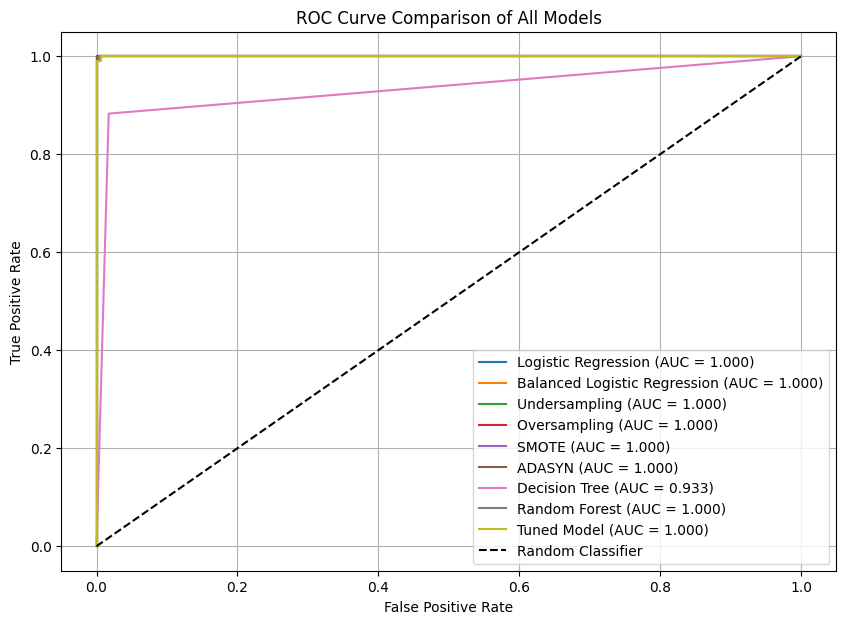

In [315]:
# 23. Plot and Interpret ROC curves for all models

models = {
    'Logistic Regression': lr,
    'Balanced Logistic Regression': lr_bal,
    'Undersampling': lr_under,
    'Oversampling': lr_over,
    'SMOTE': lr_sm,
    'ADASYN': lr_ada,
    'Decision Tree': dt,
    'Random Forest': rf,
    'Tuned Model': best_grid_model}

plt.figure(figsize=(10, 7))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')


plt.plot([0, 1], [0, 1], linestyle='--', color='black',
         label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison of All Models')
plt.legend(loc='lower right')
plt.grid()
plt.show()

In [316]:
'''
ROC Curve Interpretation:
The ROC curve is used to evaluate the performance of classification models.
- Logistic Regression and its balanced, undersampling and oversampling versions achieved excellent AUC scores of approximately 1.00.
- SMOTE and ADASYN also showed excellent performance.
- Random Forest and the Tuned Model achieved similarly high AUC scores.
- Decision Tree achieved a comparatively lower AUC score of approximately 0.933.

Conclusion: Overall, all models performed well in distinguishing between High Risk and Low Risk customers. 
Logistic Regression-based models demonstrated the highest classification performance.

'''

'\nROC Curve Interpretation:\nThe ROC curve is used to evaluate the performance of classification models.\n- Logistic Regression and its balanced, undersampling and oversampling versions achieved excellent AUC scores of approximately 1.00.\n- SMOTE and ADASYN also showed excellent performance.\n- Random Forest and the Tuned Model achieved similarly high AUC scores.\n- Decision Tree achieved a comparatively lower AUC score of approximately 0.933.\n\nConclusion: Overall, all models performed well in distinguishing between High Risk and Low Risk customers. \nLogistic Regression-based models demonstrated the highest classification performance.\n\n'

In [317]:
# 24. compute and compare AUC-ROC scores for all models

auc_scores = {}

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_prob)
    auc_scores[name] = auc

for name, auc in auc_scores.items():
    print(f'{name}: {auc}')

Logistic Regression: 1.0
Balanced Logistic Regression: 1.0
Undersampling: 1.0
Oversampling: 1.0
SMOTE: 0.9999888640185303
ADASYN: 0.9999888640185303
Decision Tree: 0.9327887838394636
Random Forest: 0.9999665920555908
Tuned Model: 0.9999443200926513


In [318]:
# 25. select the best performing model based on business requirements(minimizing false negatives)
fn_scores = {name: sum((y_test == 'High Risk') & (model.predict(X_test) == 'Low Risk'))
             for name, model in models.items()}
best_model = min(fn_scores, key=fn_scores.get)
print('Best Model:', best_model)
print('False Negatives:', fn_scores[best_model])

Best Model: Logistic Regression
False Negatives: 0


In [319]:
'''
Based on the business requirement of minimizing false negatives, Logistic Regression is selected as the best-performing model.
In risk alert classification, false negatives are critical because they represent high-risk customers incorrectly identified as low-risk. 
Logistic Regression achieved 100% recall and zero false negatives on the test dataset.
Therefore, Logistic Regression is the preferred model because it successfully identified all high-risk customers in the test data, 
reducing the possibility of missing customers who require attention.

'''

'\nBased on the business requirement of minimizing false negatives, Logistic Regression is selected as the best-performing model.\nIn risk alert classification, false negatives are critical because they represent high-risk customers incorrectly identified as low-risk. \nLogistic Regression achieved 100% recall and zero false negatives on the test dataset.\nTherefore, Logistic Regression is the preferred model because it successfully identified all high-risk customers in the test data, \nreducing the possibility of missing customers who require attention.\n\n'

### Part H: Final analysis and Reporting

In [321]:
'''
1. Best Classification Model and Justification
After comparing all the classification models, 
Logistic Regression was selected as the best-performing model based on the business requirement of minimizing false negatives.
It achieved:
- Accuracy: 100%
- Precision: 100%
- Recall: 100%
- F1 Score: 100%
- AUC-ROC: 1.00
- False Negatives: 0
The model successfully identified all high-risk cases in the test dataset. Therefore, Logistic Regression is preferred for this project.

2. Impact of Imbalance Techniques
Since the dataset contains more Low Risk cases than High Risk cases, different techniques were applied to handle class imbalance.
The techniques included:
- Undersampling
- Oversampling
- SMOTE
- ADASYN
All techniques achieved 100% recall, but their F1 scores decreased slightly from 1.00 to approximately 0.9867. 
The original Logistic Regression model performed better than the balanced versions.
This indicates that applying imbalance techniques did not improve the model's performance on the test dataset.

3. Comparison of Performance Metrics
Different models were evaluated using Accuracy, Precision, Recall, F1 Score and AUC-ROC.
Logistic Regression achieved the best overall results, with all major performance metrics reaching 100%. 
Random Forest and Tuned Random Forest also showed excellent performance, with accuracy of approximately 99.57% and 99.78%, respectively.
Decision Tree showed comparatively lower performance, with an AUC-ROC score of approximately 0.933.
Overall, Logistic Regression provided the best results among the evaluated models.

4. Business Interpretation of False Positives and False Negatives
False Positive (FP): A Low Risk customer is incorrectly classified as High Risk.
Business impact:
- Unnecessary risk alerts.
- Extra investigation and operational costs.
- Wastage of business resources.

False Negative (FN): A High Risk customer is incorrectly classified as Low Risk.
Business impact:
- Important risk cases may go unnoticed.
- Potential financial losses.
- Failure to identify customers who require attention.

In this project, false negatives are more critical because missing a high-risk customer can have serious business consequences. 
Therefore, recall is an important metric for selecting the final model.

'''

"\n1. Best Classification Model and Justification\nAfter comparing all the classification models, \nLogistic Regression was selected as the best-performing model based on the business requirement of minimizing false negatives.\nIt achieved:\n- Accuracy: 100%\n- Precision: 100%\n- Recall: 100%\n- F1 Score: 100%\n- AUC-ROC: 1.00\n- False Negatives: 0\nThe model successfully identified all high-risk cases in the test dataset. Therefore, Logistic Regression is preferred for this project.\n\n2. Impact of Imbalance Techniques\nSince the dataset contains more Low Risk cases than High Risk cases, different techniques were applied to handle class imbalance.\nThe techniques included:\n- Undersampling\n- Oversampling\n- SMOTE\n- ADASYN\nAll techniques achieved 100% recall, but their F1 scores decreased slightly from 1.00 to approximately 0.9867. \nThe original Logistic Regression model performed better than the balanced versions.\nThis indicates that applying imbalance techniques did not improve 